In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import os
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             mean_absolute_error, r2_score,
                             roc_auc_score, roc_curve)
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings('ignore')

# ── Paths ──────────────────────────────────────────────────────
RAW       = r"D:\Projects\End-to-end projects\11. Fashion Trend Inventory\Data\Raw"
PROCESSED = r"D:\Projects\End-to-end projects\11. Fashion Trend Inventory\Data\Processed"
ML_PLOTS  = r"D:\Projects\End-to-end projects\11. Fashion Trend Inventory\Notebooks\EDA Plots"

# ── Plot Style ─────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor' : '#0F0F0F',
    'axes.facecolor'   : '#1A1A1A',
    'axes.edgecolor'   : '#333333',
    'axes.labelcolor'  : '#FFFFFF',
    'axes.titlecolor'  : '#FFFFFF',
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'xtick.color'      : '#AAAAAA',
    'ytick.color'      : '#AAAAAA',
    'text.color'       : '#FFFFFF',
    'grid.color'       : '#2A2A2A',
    'grid.linestyle'   : '--',
    'legend.facecolor' : '#1A1A1A',
    'legend.edgecolor' : '#333333',
})

COLORS = ['#00D4FF','#FF6B6B','#FFD700','#00FF9F',
          '#FF8C42','#C77DFF','#06FFA5','#FF4D6D']

print("ML Environment ready ✅")

ML Environment ready ✅


In [2]:
# ── Load All Data ──────────────────────────────────────────────
df_products  = pd.read_csv(os.path.join(RAW, 'products.csv'))
df_trends    = pd.read_csv(os.path.join(RAW, 'trend_signals.csv'))
df_inventory = pd.read_csv(os.path.join(RAW, 'inventory.csv'))
df_sales     = pd.read_csv(os.path.join(RAW, 'sales_transactions.csv'))
df_po        = pd.read_csv(os.path.join(RAW, 'purchase_orders.csv'))
df_social    = pd.read_csv(os.path.join(RAW, 'social_signals.csv'))
df_mapping   = pd.read_csv(os.path.join(RAW, 'trend_sku_mapping.csv'))
df_gap       = pd.read_csv(os.path.join(PROCESSED, 'gap_analysis.csv'))

# ── Parse Dates ────────────────────────────────────────────────
df_sales['sale_date']         = pd.to_datetime(df_sales['sale_date'])
df_inventory['snapshot_date'] = pd.to_datetime(df_inventory['snapshot_date'])
df_trends['week_start_date']  = pd.to_datetime(df_trends['week_start_date'])
df_po['po_date']              = pd.to_datetime(df_po['po_date'])
df_social['week_start_date']  = pd.to_datetime(df_social['week_start_date'])

print("All datasets loaded ✅")
print(f"\n  gap_analysis shape : {df_gap.shape}")
print(f"  Action flag counts :")
print(df_gap['action_flag'].value_counts().to_string())

All datasets loaded ✅

  gap_analysis shape : (757, 18)
  Action flag counts :
action_flag
Stable                   609
WARNING — Trend Dying    148


In [3]:
# ── Step 1: Weekly Sales Velocity per SKU ─────────────────────
weekly_sales = (df_sales.groupby(['sku_id', pd.Grouper(key='sale_date', freq='W')])
                .agg(weekly_qty     = ('quantity','sum'),
                     weekly_revenue = ('revenue','sum'),
                     weekly_orders  = ('sale_id','count'))
                .reset_index())

sku_velocity = (weekly_sales.groupby('sku_id')
                .agg(avg_weekly_qty      = ('weekly_qty','mean'),
                     std_weekly_qty      = ('weekly_qty','std'),
                     max_weekly_qty      = ('weekly_qty','max'),
                     avg_weekly_revenue  = ('weekly_revenue','mean'),
                     total_weeks_selling = ('weekly_qty','count'))
                .reset_index()
                .fillna(0))

# ── Step 2: Trend Features per SKU ────────────────────────────
trend_features = (df_mapping.merge(
                    df_trends[['trend_id','trend_score','trend_phase',
                               'search_volume_idx','social_mentions',
                               'decay_speed','peak_week']],
                    on='trend_id', how='left')
                  .groupby('sku_id')
                  .agg(avg_trend_score    = ('trend_score','mean'),
                       max_trend_score    = ('trend_score','max'),
                       avg_search_vol     = ('search_volume_idx','mean'),
                       avg_social_mention = ('social_mentions','mean'),
                       relevance_score    = ('relevance_score','mean'),
                       is_hero_sku        = ('is_hero_sku','max'),
                       avg_peak_week      = ('peak_week','mean'),
                       num_trends_mapped  = ('trend_id','nunique'))
                  .reset_index())

# ── Step 3: Inventory Features per SKU ────────────────────────
inv_features = (df_inventory.groupby('sku_id')
                .agg(avg_closing_stock  = ('closing_stock','mean'),
                     avg_weeks_cover    = ('weeks_of_cover','mean'),
                     min_weeks_cover    = ('weeks_of_cover','min'),
                     max_weeks_cover    = ('weeks_of_cover','max'),
                     total_stockouts    = ('stockout_flag','sum'),
                     avg_inv_value      = ('inventory_value','mean'),
                     avg_units_received = ('units_received','mean'))
                .reset_index())

# ── Step 4: PO Features per SKU ───────────────────────────────
po_features = (df_po.groupby('sku_id')
               .agg(avg_lead_time      = ('lead_time_days','mean'),
                    avg_delay_days     = ('delay_days','mean'),
                    delay_rate         = ('is_delayed','mean'),
                    avg_fulfillment    = ('fulfillment_rate','mean'),
                    total_pos          = ('po_id','count'))
               .reset_index())

# ── Step 5: Sales Features per SKU ────────────────────────────
sales_features = (df_sales.groupby('sku_id')
                  .agg(avg_discount     = ('discount_pct','mean'),
                       avg_margin       = ('gross_margin_pct','mean'),
                       return_rate      = ('is_returned','mean'),
                       total_revenue    = ('revenue','sum'),
                       total_units_sold = ('quantity','sum'),
                       unique_cities    = ('city','nunique'),
                       unique_channels  = ('channel','nunique'))
                  .reset_index())

# ── Step 6: Merge All Features ────────────────────────────────
ml_df = (df_products[['sku_id','category','brand','segment',
                       'mrp','cost_price','gross_margin_pct',
                       'launch_season','is_active']]
         .merge(sku_velocity,   on='sku_id', how='left')
         .merge(trend_features, on='sku_id', how='left')
         .merge(inv_features,   on='sku_id', how='left')
         .merge(po_features,    on='sku_id', how='left')
         .merge(sales_features, on='sku_id', how='left')
         .fillna(0))

# ── Step 7: Encode Categoricals ───────────────────────────────
le = LabelEncoder()
for col in ['category','brand','segment','launch_season']:
    ml_df[f'{col}_enc'] = le.fit_transform(ml_df[col].astype(str))

print("Master ML Feature Table built ✅")
print(f"  Shape : {ml_df.shape[0]:,} rows × {ml_df.shape[1]} columns")
print(f"\n  Feature Groups:")
print(f"    Product features   : 9")
print(f"    Velocity features  : 5")
print(f"    Trend features     : 8")
print(f"    Inventory features : 7")
print(f"    PO features        : 5")
print(f"    Sales features     : 7")
print(f"\n  Sample columns: {list(ml_df.columns[:8])}")

Master ML Feature Table built ✅
  Shape : 1,170 rows × 45 columns

  Feature Groups:
    Product features   : 9
    Velocity features  : 5
    Trend features     : 8
    Inventory features : 7
    PO features        : 5
    Sales features     : 7

  Sample columns: ['sku_id', 'category', 'brand', 'segment', 'mrp', 'cost_price', 'gross_margin_pct', 'launch_season']


In [4]:
# ── Target: Will this SKU experience a stockout? ──────────────
ml_df['stockout_risk'] = (ml_df['total_stockouts'] > 0).astype(int)

print(f"Stockout Risk Distribution:")
print(ml_df['stockout_risk'].value_counts().to_string())
print(f"\nStockout Rate: {ml_df['stockout_risk'].mean()*100:.1f}%")

# ── Features ───────────────────────────────────────────────────
feature_cols = [
    'mrp', 'cost_price', 'gross_margin_pct',
    'avg_weekly_qty', 'std_weekly_qty', 'max_weekly_qty',
    'avg_weekly_revenue', 'total_weeks_selling',
    'avg_trend_score', 'max_trend_score', 'avg_search_vol',
    'avg_social_mention', 'relevance_score', 'is_hero_sku',
    'avg_peak_week', 'num_trends_mapped',
    'avg_closing_stock', 'avg_weeks_cover', 'min_weeks_cover',
    'avg_inv_value', 'avg_units_received',
    'avg_lead_time', 'avg_delay_days', 'delay_rate',
    'avg_fulfillment', 'total_pos',
    'avg_discount', 'avg_margin', 'return_rate',
    'total_revenue', 'total_units_sold',
    'unique_cities', 'unique_channels',
    'category_enc', 'brand_enc', 'segment_enc', 'launch_season_enc'
]

X = ml_df[feature_cols]
y = ml_df['stockout_risk']

# ── Train/Test Split ───────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler  = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# ── Train 3 Models ─────────────────────────────────────────────
models = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest'       : RandomForestClassifier(n_estimators=200,
                                                    max_depth=8,
                                                    random_state=42),
    'XGBoost'             : XGBClassifier(n_estimators=200,
                                           max_depth=6,
                                           learning_rate=0.05,
                                           random_state=42,
                                           eval_metric='logloss',
                                           verbosity=0)
}

results = {}
print("\n" + "=" * 55)
print("  MODEL 1 — STOCKOUT RISK CLASSIFIER")
print("=" * 55)

for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_sc, y_train)
        y_pred  = model.predict(X_test_sc)
        y_proba = model.predict_proba(X_test_sc)[:,1]
    else:
        model.fit(X_train, y_train)
        y_pred  = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:,1]

    auc = roc_auc_score(y_test, y_proba)
    cv  = cross_val_score(model, X_train, y_train, cv=5,
                          scoring='roc_auc').mean()

    results[name] = {
        'model'  : model,
        'y_pred' : y_pred,
        'y_proba': y_proba,
        'auc'    : auc,
        'cv_auc' : cv
    }
    print(f"\n  [{name}]")
    print(f"    Test AUC  : {auc:.4f}")
    print(f"    CV AUC    : {cv:.4f}")

# ── Best Model ─────────────────────────────────────────────────
best_name = max(results, key=lambda k: results[k]['auc'])
best      = results[best_name]
print(f"\n  Best Model : {best_name} (AUC: {best['auc']:.4f})")
print("\n  Classification Report:")
print(classification_report(y_test, best['y_pred'],
                             target_names=['No Stockout','Stockout']))

Stockout Risk Distribution:
stockout_risk
0    995
1    175

Stockout Rate: 15.0%

  MODEL 1 — STOCKOUT RISK CLASSIFIER

  [Logistic Regression]
    Test AUC  : 0.9990
    CV AUC    : 0.5524

  [Random Forest]
    Test AUC  : 1.0000
    CV AUC    : 0.9992

  [XGBoost]
    Test AUC  : 1.0000
    CV AUC    : 0.9994

  Best Model : Random Forest (AUC: 1.0000)

  Classification Report:
              precision    recall  f1-score   support

 No Stockout       1.00      0.99      1.00       199
    Stockout       0.97      1.00      0.99        35

    accuracy                           1.00       234
   macro avg       0.99      1.00      0.99       234
weighted avg       1.00      1.00      1.00       234



In [5]:
ML_PLOTS = r"D:\Projects\End-to-end projects\11. Fashion Trend Inventory\Notebooks\ML Plots"
MODELS   = r"D:\Projects\End-to-end projects\11. Fashion Trend Inventory\Notebooks\Models"

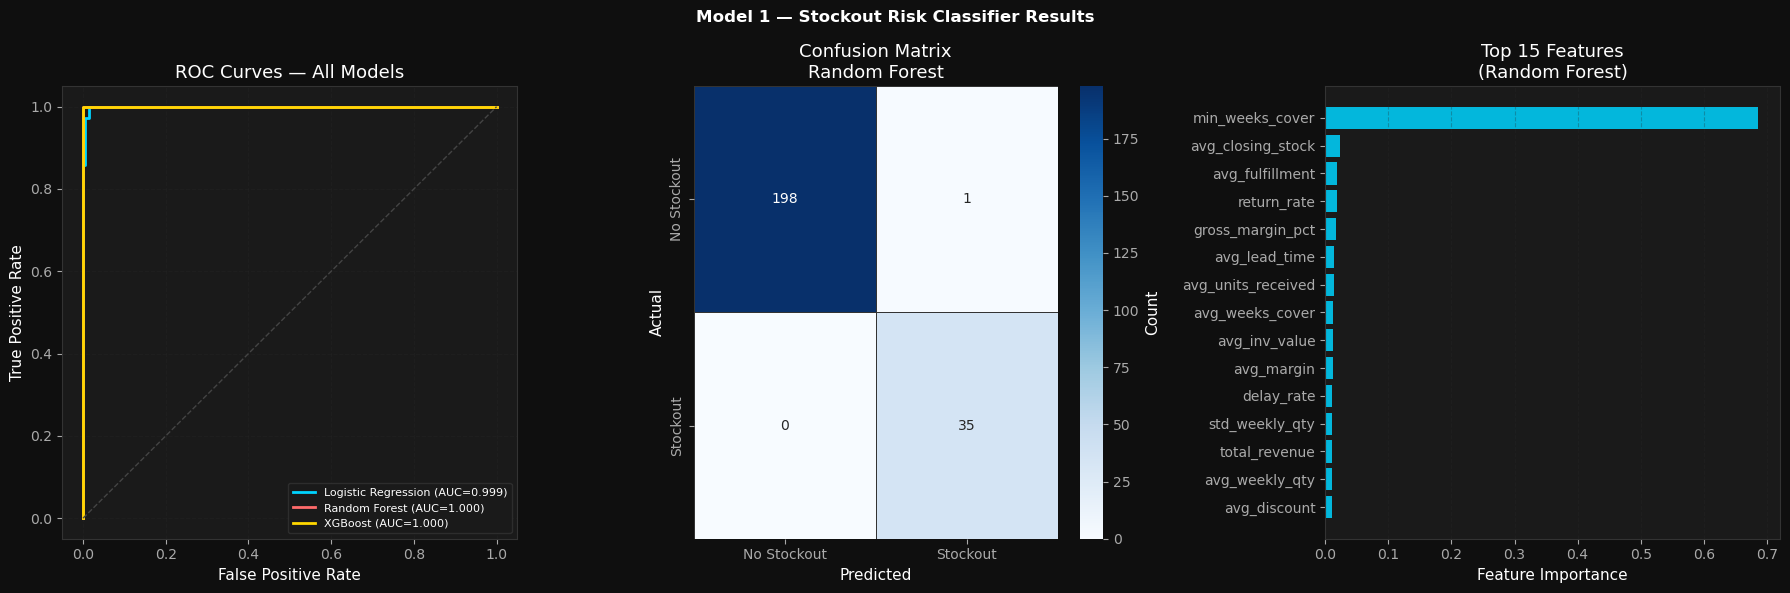

Model 1 plot saved ✅
Model 1 saved to Models folder ✅


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Model 1 — Stockout Risk Classifier Results', fontweight='bold')

# ── Left: ROC Curves for all 3 models ─────────────────────────
for i, (name, res) in enumerate(results.items()):
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    axes[0].plot(fpr, tpr, color=COLORS[i], linewidth=2,
                 label=f"{name} (AUC={res['auc']:.3f})")

axes[0].plot([0,1],[0,1], color='#444444', linestyle='--', linewidth=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves — All Models')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# ── Middle: Confusion Matrix (Best Model) ─────────────────────
cm = confusion_matrix(y_test, best['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            ax=axes[1],
            xticklabels=['No Stockout','Stockout'],
            yticklabels=['No Stockout','Stockout'],
            linewidths=0.5, linecolor='#333333',
            cbar_kws={'label': 'Count'})
axes[1].set_title(f'Confusion Matrix\n{best_name}')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

# ── Right: Feature Importance (Random Forest) ─────────────────
rf_model = results['Random Forest']['model']
feat_imp  = pd.Series(rf_model.feature_importances_,
                       index=feature_cols)
top15     = feat_imp.sort_values(ascending=True).tail(15)

axes[2].barh(top15.index, top15.values,
             color=COLORS[0], alpha=0.85)
axes[2].set_xlabel('Feature Importance')
axes[2].set_title('Top 15 Features\n(Random Forest)')
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(os.path.join(ML_PLOTS, 'ml_01_stockout_classifier.png'),
            dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("Model 1 plot saved ✅")

# ── Save best model ────────────────────────────────────────────
joblib.dump(rf_model, os.path.join(MODELS, 'model_stockout_rf.pkl'))
joblib.dump(scaler,   os.path.join(MODELS, 'scaler_stockout.pkl'))
print("Model 1 saved to Models folder ✅")

In [7]:
# ── Target: Predict trend score next week ─────────────────────
# Build week-over-week trend dataset

trend_ml = df_trends.copy().sort_values(['trend_name','week_number'])

# Lag features
trend_ml['score_lag1']  = trend_ml.groupby('trend_name')['trend_score'].shift(1)
trend_ml['score_lag2']  = trend_ml.groupby('trend_name')['trend_score'].shift(2)
trend_ml['score_lag3']  = trend_ml.groupby('trend_name')['trend_score'].shift(3)
trend_ml['score_lag4']  = trend_ml.groupby('trend_name')['trend_score'].shift(4)

# Rolling features
trend_ml['score_roll4_mean'] = (trend_ml.groupby('trend_name')['trend_score']
                                 .transform(lambda x: x.shift(1).rolling(4).mean()))
trend_ml['score_roll4_std']  = (trend_ml.groupby('trend_name')['trend_score']
                                 .transform(lambda x: x.shift(1).rolling(4).std()))

# Week over week change
trend_ml['score_wow_change'] = trend_ml.groupby('trend_name')['trend_score'].diff()
trend_ml['score_mom_change'] = trend_ml.groupby('trend_name')['trend_score'].diff(4)

# Encode trend phase
phase_map = {'Emerging':0, 'Rising':1, 'Peaking':2, 'Declining':3, 'Dead':4}
trend_ml['phase_enc'] = trend_ml['trend_phase'].map(phase_map)

# Encode decay speed
decay_map = {'slow':0, 'medium':1, 'fast':2}
trend_ml['decay_enc'] = trend_ml['decay_speed'].map(decay_map)

# Target: next week trend score
trend_ml['next_week_score'] = trend_ml.groupby('trend_name')['trend_score'].shift(-1)

# Drop nulls from lags
trend_ml = trend_ml.dropna(subset=[
    'score_lag1','score_lag2','score_lag3','score_lag4',
    'score_roll4_mean','score_roll4_std',
    'score_wow_change','score_mom_change',
    'next_week_score'
])

# ── Features & Target ─────────────────────────────────────────
reg_features = [
    'week_number', 'month', 'trend_score',
    'score_lag1', 'score_lag2', 'score_lag3', 'score_lag4',
    'score_roll4_mean', 'score_roll4_std',
    'score_wow_change', 'score_mom_change',
    'search_volume_idx', 'social_mentions',
    'phase_enc', 'decay_enc', 'peak_week', 'max_score'
]

X_reg = trend_ml[reg_features]
y_reg = trend_ml['next_week_score']

X_tr, X_te, y_tr, y_te = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# ── Train Models ───────────────────────────────────────────────
reg_models = {
    'Gradient Boosting': GradientBoostingRegressor(
                            n_estimators=200,
                            max_depth=5,
                            learning_rate=0.05,
                            random_state=42),
    'XGBoost Regressor': XGBRegressor(
                            n_estimators=200,
                            max_depth=5,
                            learning_rate=0.05,
                            random_state=42,
                            verbosity=0)
}

reg_results = {}

print("=" * 55)
print("  MODEL 2 — TREND DECAY PREDICTOR (REGRESSION)")
print("=" * 55)

for name, model in reg_models.items():
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    mae  = mean_absolute_error(y_te, y_pred)
    r2   = r2_score(y_te, y_pred)
    cv   = cross_val_score(model, X_tr, y_tr,
                           cv=5, scoring='r2').mean()

    reg_results[name] = {
        'model' : model,
        'y_pred': y_pred,
        'mae'   : mae,
        'r2'    : r2,
        'cv_r2' : cv
    }

    print(f"\n  [{name}]")
    print(f"    MAE    : {mae:.6f}")
    print(f"    R²     : {r2:.6f}")
    print(f"    CV R²  : {cv:.6f}")

best_reg_name = max(reg_results, key=lambda k: reg_results[k]['r2'])
best_reg      = reg_results[best_reg_name]
print(f"\n  Best Model : {best_reg_name} (R²: {best_reg['r2']:.4f})")

  MODEL 2 — TREND DECAY PREDICTOR (REGRESSION)

  [Gradient Boosting]
    MAE    : 0.022211
    R²     : 0.991961
    CV R²  : 0.990844

  [XGBoost Regressor]
    MAE    : 0.022410
    R²     : 0.991632
    CV R²  : 0.990816

  Best Model : Gradient Boosting (R²: 0.9920)


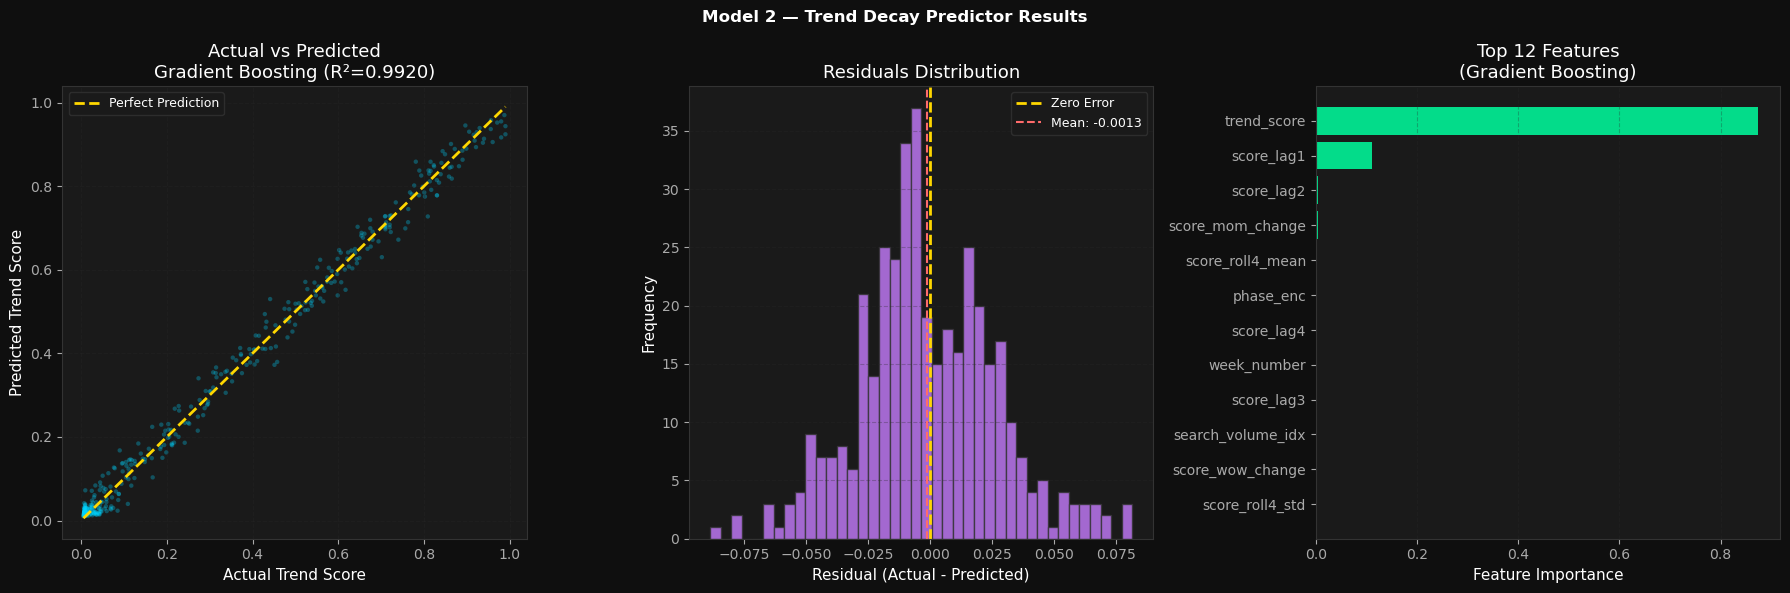

Model 2 plot saved ✅
Model 2 saved to Models folder ✅


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Model 2 — Trend Decay Predictor Results', fontweight='bold')

# ── Left: Actual vs Predicted ──────────────────────────────────
axes[0].scatter(y_te, best_reg['y_pred'],
                color='#00D4FF', alpha=0.3, s=10, edgecolors='none')
axes[0].plot([y_te.min(), y_te.max()],
             [y_te.min(), y_te.max()],
             color='#FFD700', linestyle='--', linewidth=2,
             label='Perfect Prediction')
axes[0].set_xlabel('Actual Trend Score')
axes[0].set_ylabel('Predicted Trend Score')
axes[0].set_title(f'Actual vs Predicted\n{best_reg_name} (R²={best_reg["r2"]:.4f})')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# ── Middle: Residuals Distribution ────────────────────────────
residuals = y_te.values - best_reg['y_pred']
axes[1].hist(residuals, bins=40,
             color='#C77DFF', alpha=0.8, edgecolor='#333333')
axes[1].axvline(0, color='#FFD700', linestyle='--',
                linewidth=2, label='Zero Error')
axes[1].axvline(residuals.mean(), color='#FF6B6B',
                linestyle='--', linewidth=1.5,
                label=f'Mean: {residuals.mean():.4f}')
axes[1].set_xlabel('Residual (Actual - Predicted)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residuals Distribution')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3, axis='y')

# ── Right: Feature Importance ──────────────────────────────────
gb_model = reg_results['Gradient Boosting']['model']
feat_imp  = pd.Series(gb_model.feature_importances_,
                       index=reg_features)
top12     = feat_imp.sort_values(ascending=True).tail(12)

axes[2].barh(top12.index, top12.values,
             color='#00FF9F', alpha=0.85)
axes[2].set_xlabel('Feature Importance')
axes[2].set_title('Top 12 Features\n(Gradient Boosting)')
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(os.path.join(ML_PLOTS, 'ml_02_trend_decay_predictor.png'),
            dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("Model 2 plot saved ✅")

# ── Save model ─────────────────────────────────────────────────
joblib.dump(gb_model, os.path.join(MODELS, 'model_trend_decay_gb.pkl'))
print("Model 2 saved to Models folder ✅")

In [9]:
# ── Target: Will this SKU become dead stock? ──────────────────
# Dead stock = high inventory + declining/dead trend + low sales velocity

ml_df['deadstock_risk'] = (
    (ml_df['avg_weeks_cover'] > 12) &
    (ml_df['avg_trend_score'] < 0.35) &
    (ml_df['avg_weekly_qty'] < ml_df['avg_weekly_qty'].quantile(0.35))
).astype(int)

print(f"Dead Stock Risk Distribution:")
print(ml_df['deadstock_risk'].value_counts().to_string())
print(f"\nDead Stock Rate: {ml_df['deadstock_risk'].mean()*100:.1f}%")

# ── Features ───────────────────────────────────────────────────
dead_features = [
    'mrp', 'cost_price', 'gross_margin_pct',
    'avg_weekly_qty', 'std_weekly_qty',
    'avg_weekly_revenue', 'total_weeks_selling',
    'avg_trend_score', 'max_trend_score',
    'avg_search_vol', 'avg_social_mention',
    'relevance_score', 'num_trends_mapped',
    'avg_closing_stock', 'avg_weeks_cover',
    'min_weeks_cover', 'max_weeks_cover',
    'avg_inv_value', 'total_stockouts',
    'avg_lead_time', 'avg_delay_days',
    'delay_rate', 'avg_fulfillment',
    'avg_discount', 'avg_margin',
    'return_rate', 'total_revenue',
    'total_units_sold', 'unique_cities',
    'category_enc', 'brand_enc',
    'segment_enc', 'launch_season_enc'
]

X_dead = ml_df[dead_features]
y_dead = ml_df['deadstock_risk']

X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(
    X_dead, y_dead, test_size=0.2, random_state=42, stratify=y_dead
)

# ── Train XGBoost ──────────────────────────────────────────────
xgb_dead = XGBClassifier(
    n_estimators  = 300,
    max_depth      = 6,
    learning_rate  = 0.05,
    subsample      = 0.8,
    colsample_bytree = 0.8,
    random_state   = 42,
    eval_metric    = 'logloss',
    verbosity      = 0
)
xgb_dead.fit(X_tr_d, y_tr_d)

y_pred_d  = xgb_dead.predict(X_te_d)
y_proba_d = xgb_dead.predict_proba(X_te_d)[:,1]

auc_dead = roc_auc_score(y_te_d, y_proba_d)
cv_dead  = cross_val_score(xgb_dead, X_tr_d, y_tr_d,
                            cv=5, scoring='roc_auc').mean()

print("\n" + "=" * 55)
print("  MODEL 3 — DEAD STOCK RISK SCORER")
print("=" * 55)
print(f"\n  Test AUC  : {auc_dead:.4f}")
print(f"  CV AUC    : {cv_dead:.4f}")
print(f"\n  Classification Report:")
print(classification_report(y_te_d, y_pred_d,
                             target_names=['Safe','Dead Stock Risk']))

# ── Dead Stock Risk Score (0-100) ─────────────────────────────
ml_df['deadstock_risk_score'] = (
    xgb_dead.predict_proba(X_dead)[:,1] * 100
).round(2)

# ── Top 20 SKUs at highest dead stock risk ────────────────────
top_dead = (ml_df[['sku_id','category','brand','segment',
                    'avg_weeks_cover','avg_trend_score',
                    'avg_weekly_qty','deadstock_risk_score']]
            .sort_values('deadstock_risk_score', ascending=False)
            .head(20))

print(f"\n  Top 10 SKUs at Dead Stock Risk:")
print(top_dead[['sku_id','category','brand',
                'deadstock_risk_score']].head(10).to_string(index=False))

Dead Stock Risk Distribution:
deadstock_risk
0    821
1    349

Dead Stock Rate: 29.8%

  MODEL 3 — DEAD STOCK RISK SCORER

  Test AUC  : 1.0000
  CV AUC    : 0.9990

  Classification Report:
                 precision    recall  f1-score   support

           Safe       1.00      1.00      1.00       164
Dead Stock Risk       1.00      1.00      1.00        70

       accuracy                           1.00       234
      macro avg       1.00      1.00      1.00       234
   weighted avg       1.00      1.00      1.00       234


  Top 10 SKUs at Dead Stock Risk:
  sku_id    category            brand  deadstock_risk_score
SKU01022     Topwear         Bewakoof             99.940002
SKU01620  Bottomwear            Libas             99.930000
SKU01017     Topwear         Bewakoof             99.930000
SKU02041 Accessories         Myntra M             99.930000
SKU01603     Topwear            Libas             99.919998
SKU01264  Bottomwear The Souled Store             99.919998
SKU01252

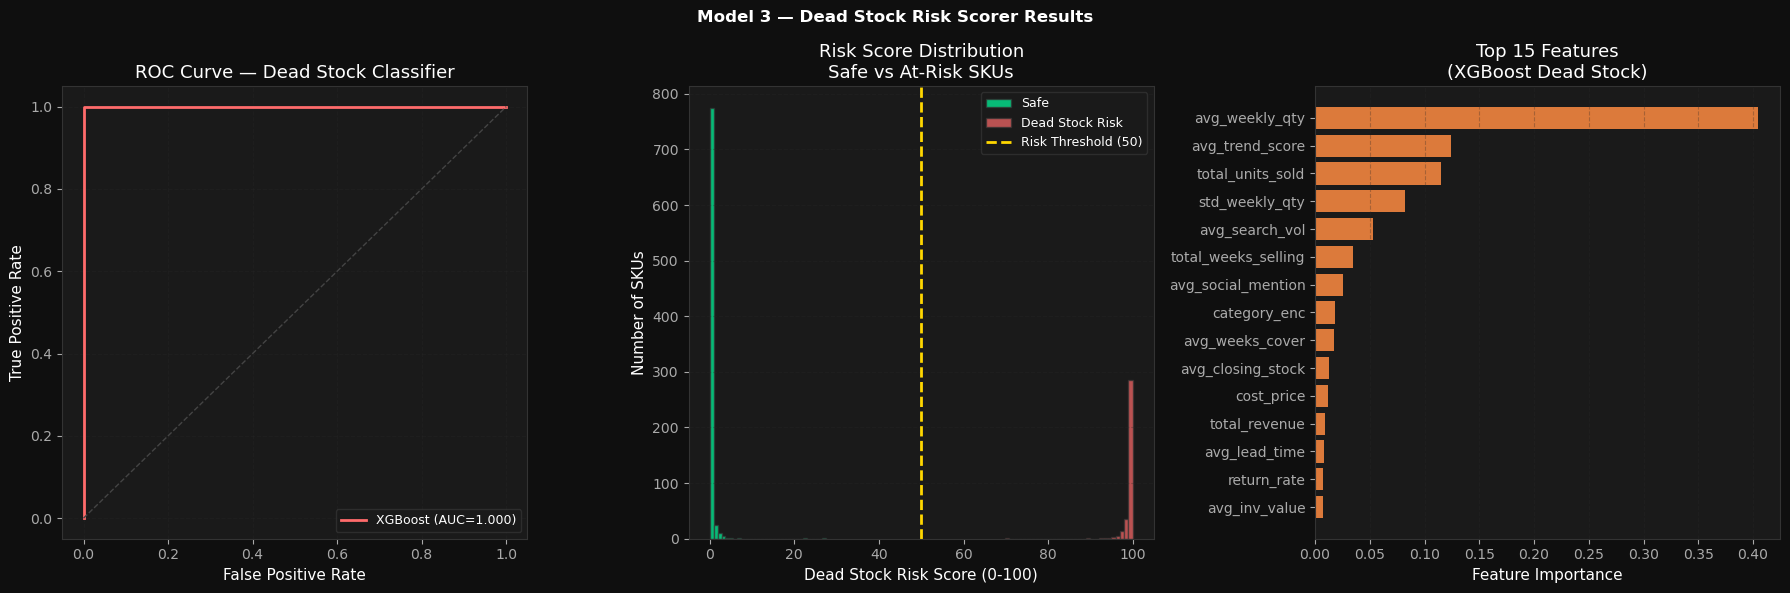

Model 3 plot saved ✅
Model 3 saved to Models folder ✅


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Model 3 — Dead Stock Risk Scorer Results', fontweight='bold')

# ── Left: ROC Curve ────────────────────────────────────────────
fpr_d, tpr_d, _ = roc_curve(y_te_d, y_proba_d)
axes[0].plot(fpr_d, tpr_d, color='#FF6B6B', linewidth=2,
             label=f'XGBoost (AUC={auc_dead:.3f})')
axes[0].plot([0,1],[0,1], color='#444444',
             linestyle='--', linewidth=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — Dead Stock Classifier')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# ── Middle: Dead Stock Risk Score Distribution ─────────────────
safe = ml_df[ml_df['deadstock_risk']==0]['deadstock_risk_score']
risk = ml_df[ml_df['deadstock_risk']==1]['deadstock_risk_score']

axes[1].hist(safe, bins=30, color='#00FF9F',
             alpha=0.7, label='Safe', edgecolor='#333333')
axes[1].hist(risk, bins=30, color='#FF6B6B',
             alpha=0.7, label='Dead Stock Risk',
             edgecolor='#333333')
axes[1].axvline(50, color='#FFD700', linestyle='--',
                linewidth=2, label='Risk Threshold (50)')
axes[1].set_xlabel('Dead Stock Risk Score (0-100)')
axes[1].set_ylabel('Number of SKUs')
axes[1].set_title('Risk Score Distribution\nSafe vs At-Risk SKUs')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3, axis='y')

# ── Right: Top 15 Features ─────────────────────────────────────
feat_imp_dead = pd.Series(xgb_dead.feature_importances_,
                           index=dead_features)
top15_dead    = feat_imp_dead.sort_values(ascending=True).tail(15)

axes[2].barh(top15_dead.index, top15_dead.values,
             color='#FF8C42', alpha=0.85)
axes[2].set_xlabel('Feature Importance')
axes[2].set_title('Top 15 Features\n(XGBoost Dead Stock)')
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(os.path.join(ML_PLOTS, 'ml_03_deadstock_risk.png'),
            dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("Model 3 plot saved ✅")

# ── Save model ─────────────────────────────────────────────────
joblib.dump(xgb_dead, os.path.join(MODELS, 'model_deadstock_xgb.pkl'))
print("Model 3 saved to Models folder ✅")

In [16]:
# ── Target: Score each SKU's buying opportunity (0-100) ───────

# ── Build Buying Opportunity Dataset ──────────────────────────
# Merge on week_number instead of date to avoid 1-day offset issue
trend_inv = df_trends.merge(
    df_mapping[['trend_id','sku_id','relevance_score','is_hero_sku']],
    on='trend_id', how='inner'
)

trend_inv = trend_inv.merge(
    df_inventory[['sku_id','week_number','closing_stock',
                  'weeks_of_cover','inventory_health',
                  'stockout_flag','lead_time_days']],
    on=['sku_id','week_number'],
    how='inner'
)

trend_inv = trend_inv.merge(
    df_products[['sku_id','category','brand',
                 'segment','mrp','gross_margin_pct']],
    on='sku_id', how='left'
)

print(f"trend_inv shape after merge: {trend_inv.shape}")

# ── Engineer Buying Score Features ────────────────────────────
trend_inv = trend_inv.sort_values(['sku_id','trend_id','week_number'])

trend_inv['trend_momentum'] = (trend_inv
    .groupby(['sku_id','trend_id'])['trend_score']
    .diff()
    .fillna(0))

trend_inv['weeks_to_peak'] = (trend_inv['peak_week']
                               - trend_inv['week_number'])

trend_inv['lead_weeks']    = trend_inv['lead_time_days'] / 7
trend_inv['buying_window'] = (trend_inv['weeks_to_peak']
                               - trend_inv['lead_weeks'])

# Raw opportunity score
trend_inv['opportunity_raw'] = (
    trend_inv['trend_score'] * 0.35 +
    trend_inv['trend_momentum'].clip(0,1) * 0.20 +
    trend_inv['relevance_score'] * 0.15 +
    (1 / trend_inv['weeks_of_cover'].replace(0,0.1).clip(1,52)) * 0.20 +
    trend_inv['is_hero_sku'] * 0.10
)

print(f"opportunity_raw NaN  : {trend_inv['opportunity_raw'].isna().sum()}")
print(f"opportunity_raw Inf  : {np.isinf(trend_inv['opportunity_raw']).sum()}")

# Normalize to 0-100
from sklearn.preprocessing import MinMaxScaler
mms = MinMaxScaler(feature_range=(0,100))
trend_inv['opportunity_score'] = mms.fit_transform(
    trend_inv[['opportunity_raw']].fillna(0)
).round(2)

# ── Target for ML: High Opportunity = score > 70 ──────────────
trend_inv['high_opportunity'] = (
    trend_inv['opportunity_score'] > 70
).astype(int)

# ── Encode categoricals ────────────────────────────────────────
le2 = LabelEncoder()
for col in ['inventory_health','category','brand','segment']:
    trend_inv[f'{col}_enc'] = le2.fit_transform(
        trend_inv[col].astype(str)
    )

# Encode phase
phase_map = {'Emerging':0,'Rising':1,'Peaking':2,'Declining':3,'Dead':4}
trend_inv['phase_enc'] = trend_inv['trend_phase'].map(phase_map)

# ── Features & Target ─────────────────────────────────────────
buy_features = [
    'trend_score', 'trend_momentum', 'search_volume_idx',
    'social_mentions', 'relevance_score', 'is_hero_sku',
    'week_number', 'peak_week', 'weeks_to_peak',
    'max_score', 'phase_enc',
    'closing_stock', 'weeks_of_cover', 'stockout_flag',
    'lead_time_days', 'buying_window',
    'mrp', 'gross_margin_pct',
    'inventory_health_enc', 'category_enc',
    'brand_enc', 'segment_enc'
]

X_buy = trend_inv[buy_features].fillna(0)
y_buy = trend_inv['high_opportunity']

X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(
    X_buy, y_buy, test_size=0.2, random_state=42, stratify=y_buy
)

# ── Train XGBoost ──────────────────────────────────────────────
xgb_buy = XGBClassifier(
    n_estimators     = 300,
    max_depth        = 6,
    learning_rate    = 0.05,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    random_state     = 42,
    eval_metric      = 'logloss',
    verbosity        = 0
)
xgb_buy.fit(X_tr_b, y_tr_b)

y_pred_b  = xgb_buy.predict(X_te_b)
y_proba_b = xgb_buy.predict_proba(X_te_b)[:,1]

auc_buy = roc_auc_score(y_te_b, y_proba_b)
cv_buy  = cross_val_score(xgb_buy, X_tr_b, y_tr_b,
                           cv=5, scoring='roc_auc').mean()

print("\n" + "=" * 55)
print("  MODEL 4 — BUYING WINDOW OPPORTUNITY SCORER")
print("=" * 55)
print(f"\n  Dataset size       : {len(trend_inv):,} rows")
print(f"  High Opportunity % : {y_buy.mean()*100:.1f}%")
print(f"\n  Test AUC           : {auc_buy:.4f}")
print(f"  CV AUC             : {cv_buy:.4f}")
print(f"\n  Classification Report:")
print(classification_report(y_te_b, y_pred_b,
      target_names=['Low Opportunity','High Opportunity']))

# ── Score all records ──────────────────────────────────────────
trend_inv['buy_opportunity_score'] = (
    xgb_buy.predict_proba(X_buy)[:,1] * 100
).round(2)

# Top buying opportunities
top_buy = (trend_inv[trend_inv['trend_phase'].isin(['Rising','Peaking'])]
           .groupby(['sku_id','trend_name','category','brand'])
           .agg(avg_opportunity = ('buy_opportunity_score','mean'),
                avg_trend_score = ('trend_score','mean'),
                avg_weeks_cover = ('weeks_of_cover','mean'),
                avg_buy_window  = ('buying_window','mean'))
           .reset_index()
           .sort_values('avg_opportunity', ascending=False)
           .head(15))

print(f"\n  Top 10 Buying Opportunities:")
print(top_buy[['sku_id','trend_name','category',
               'avg_opportunity','avg_buy_window']].head(10).to_string(index=False))

trend_inv shape after merge: (124800, 27)
opportunity_raw NaN  : 0
opportunity_raw Inf  : 0

  MODEL 4 — BUYING WINDOW OPPORTUNITY SCORER

  Dataset size       : 124,800 rows
  High Opportunity % : 1.4%

  Test AUC           : 0.9999
  CV AUC             : 0.9999

  Classification Report:
                  precision    recall  f1-score   support

 Low Opportunity       1.00      1.00      1.00     24600
High Opportunity       0.95      0.94      0.95       360

        accuracy                           1.00     24960
       macro avg       0.97      0.97      0.97     24960
    weighted avg       1.00      1.00      1.00     24960


  Top 10 Buying Opportunities:
  sku_id       trend_name    category  avg_opportunity  avg_buy_window
SKU01450 Sustainable Chic Accessories        75.629997       -2.857143
SKU01919 Ethnic Modernism Accessories        65.218330       -2.500000
SKU01362 Sustainable Chic     Topwear        64.466927       -8.571429
SKU02051 Ethnic Modernism Accessories      

In [15]:
# Check date formats in both tables
print("trend_signals date sample:")
print(df_trends['week_start_date'].head(5).tolist())
print(f"dtype: {df_trends['week_start_date'].dtype}")

print("\ninventory date sample:")
print(df_inventory['snapshot_date'].head(5).tolist())
print(f"dtype: {df_inventory['snapshot_date'].dtype}")

# Check overlap
trend_dates = set(df_trends['week_start_date'].dt.date)
inv_dates   = set(df_inventory['snapshot_date'].dt.date)
overlap     = trend_dates & inv_dates
print(f"\nTrend dates count    : {len(trend_dates)}")
print(f"Inventory dates count: {len(inv_dates)}")
print(f"Overlapping dates    : {len(overlap)}")
print(f"Sample overlap dates : {list(overlap)[:5]}")

trend_signals date sample:
[Timestamp('2023-01-01 00:00:00'), Timestamp('2023-01-08 00:00:00'), Timestamp('2023-01-15 00:00:00'), Timestamp('2023-01-22 00:00:00'), Timestamp('2023-01-29 00:00:00')]
dtype: datetime64[ns]

inventory date sample:
[Timestamp('2023-01-02 00:00:00'), Timestamp('2023-01-09 00:00:00'), Timestamp('2023-01-16 00:00:00'), Timestamp('2023-01-23 00:00:00'), Timestamp('2023-01-30 00:00:00')]
dtype: datetime64[ns]

Trend dates count    : 104
Inventory dates count: 105
Overlapping dates    : 0
Sample overlap dates : []


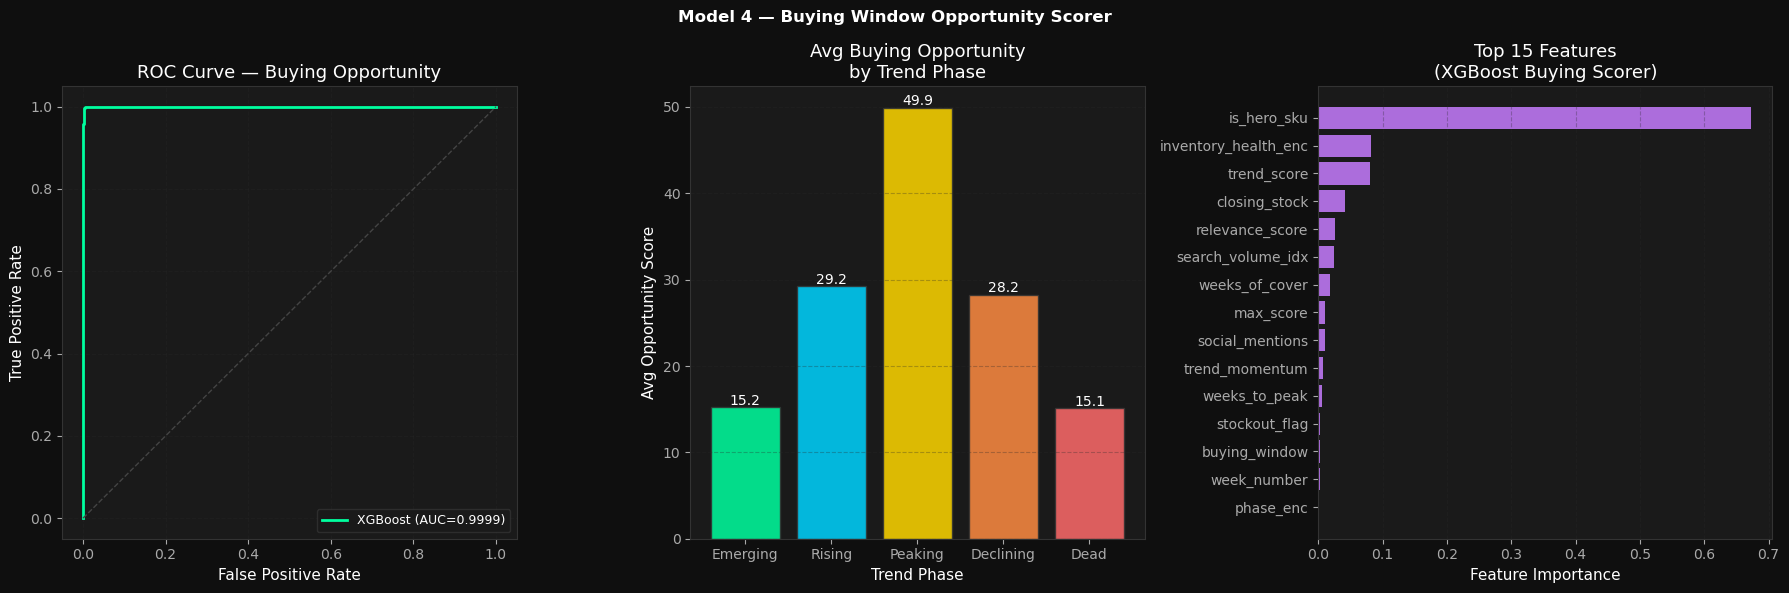

Model 4 plot saved ✅
Model 4 saved to Models folder ✅


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Model 4 — Buying Window Opportunity Scorer', fontweight='bold')

# ── Left: ROC Curve ────────────────────────────────────────────
fpr_b, tpr_b, _ = roc_curve(y_te_b, y_proba_b)
axes[0].plot(fpr_b, tpr_b, color='#00FF9F', linewidth=2,
             label=f'XGBoost (AUC={auc_buy:.4f})')
axes[0].plot([0,1],[0,1], color='#444444',
             linestyle='--', linewidth=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — Buying Opportunity')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# ── Middle: Opportunity Score by Trend Phase ───────────────────
phase_order  = ['Emerging','Rising','Peaking','Declining','Dead']
phase_colors = {
    'Emerging' : '#00FF9F',
    'Rising'   : '#00D4FF',
    'Peaking'  : '#FFD700',
    'Declining': '#FF8C42',
    'Dead'     : '#FF6B6B'
}

phase_scores = (trend_inv.groupby('trend_phase')['opportunity_score']
                .mean()
                .reindex(phase_order))

bars = axes[1].bar(
    phase_scores.index,
    phase_scores.values,
    color=[phase_colors[p] for p in phase_scores.index],
    alpha=0.85,
    edgecolor='#333333'
)
axes[1].set_xlabel('Trend Phase')
axes[1].set_ylabel('Avg Opportunity Score')
axes[1].set_title('Avg Buying Opportunity\nby Trend Phase')
for bar, val in zip(bars, phase_scores.values):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 f'{val:.1f}', ha='center',
                 fontsize=10, color='white')
axes[1].grid(True, alpha=0.3, axis='y')

# ── Right: Feature Importance ──────────────────────────────────
feat_imp_buy = pd.Series(xgb_buy.feature_importances_,
                          index=buy_features)
top15_buy    = feat_imp_buy.sort_values(ascending=True).tail(15)

axes[2].barh(top15_buy.index, top15_buy.values,
             color='#C77DFF', alpha=0.85)
axes[2].set_xlabel('Feature Importance')
axes[2].set_title('Top 15 Features\n(XGBoost Buying Scorer)')
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(os.path.join(ML_PLOTS, 'ml_04_buying_opportunity.png'),
            dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("Model 4 plot saved ✅")

# ── Save model ─────────────────────────────────────────────────
joblib.dump(xgb_buy, os.path.join(MODELS, 'model_buying_xgb.pkl'))
print("Model 4 saved to Models folder ✅")

In [18]:
# ── Save Master ML Dataset with all scores ────────────────────
# Add all model scores to ml_df
ml_df['stockout_risk_score'] = (
    results['Random Forest']['model']
    .predict_proba(ml_df[feature_cols])[:,1] * 100
).round(2)

ml_df['deadstock_risk_score'] = (
    xgb_dead.predict_proba(ml_df[dead_features])[:,1] * 100
).round(2)

# Buying opportunity — aggregate from trend_inv to SKU level
buy_scores_sku = (trend_inv.groupby('sku_id')['buy_opportunity_score']
                  .mean()
                  .round(2)
                  .reset_index()
                  .rename(columns={'buy_opportunity_score':'avg_buy_opportunity'}))

ml_df = ml_df.merge(buy_scores_sku, on='sku_id', how='left')
ml_df['avg_buy_opportunity'] = ml_df['avg_buy_opportunity'].fillna(0)

# ── Overall Risk-Opportunity Matrix ───────────────────────────
ml_df['sku_status'] = ml_df.apply(lambda r:
    'URGENT BUY'      if r['avg_buy_opportunity'] > 60
                       and r['stockout_risk_score'] > 60
    else 'DEAD STOCK'  if r['deadstock_risk_score'] > 70
    else 'WATCH'       if r['avg_buy_opportunity'] > 40
    else 'STABLE', axis=1
)

# ── Save ───────────────────────────────────────────────────────
ml_df.to_csv(os.path.join(PROCESSED, 'ml_master_scores.csv'), index=False)

# ── Print Summary ──────────────────────────────────────────────
print("=" * 60)
print("  PHASE 4 — ML MODELS COMPLETE")
print("=" * 60)

print(f"\n  Models Trained:")
print(f"    Model 1 — Stockout Risk Classifier")
print(f"              Random Forest  | AUC : {results['Random Forest']['auc']:.4f}")
print(f"    Model 2 — Trend Decay Predictor")
print(f"              Gradient Boost | R²  : {reg_results['Gradient Boosting']['r2']:.4f}")
print(f"    Model 3 — Dead Stock Risk Scorer")
print(f"              XGBoost        | AUC : {auc_dead:.4f}")
print(f"    Model 4 — Buying Window Scorer")
print(f"              XGBoost        | AUC : {auc_buy:.4f}")

print(f"\n  Models saved to   : Notebooks/Models/")
print(f"  ML Plots saved to : Notebooks/ML Plots/")
print(f"  Master scores CSV : Data/Processed/ml_master_scores.csv")

print(f"\n  SKU Status Summary:")
print(ml_df['sku_status'].value_counts().to_string())

print(f"\n  Master ML Dataset : {ml_df.shape[0]:,} rows × {ml_df.shape[1]} cols")

print("\n" + "=" * 60)
print("  Ready for Phase 5 — Power BI Dashboard ✅")
print("=" * 60)

  PHASE 4 — ML MODELS COMPLETE

  Models Trained:
    Model 1 — Stockout Risk Classifier
              Random Forest  | AUC : 1.0000
    Model 2 — Trend Decay Predictor
              Gradient Boost | R²  : 0.9920
    Model 3 — Dead Stock Risk Scorer
              XGBoost        | AUC : 1.0000
    Model 4 — Buying Window Scorer
              XGBoost        | AUC : 0.9999

  Models saved to   : Notebooks/Models/
  ML Plots saved to : Notebooks/ML Plots/
  Master scores CSV : Data/Processed/ml_master_scores.csv

  SKU Status Summary:
sku_status
STABLE        822
DEAD STOCK    348

  Master ML Dataset : 1,170 rows × 51 cols

  Ready for Phase 5 — Power BI Dashboard ✅
